# 05 · Approve, review or decline: the decision

A score is not a decision. Each payment gets the action with the lowest **expected cost**, using
the calibrated fraud probability from phase 3 and the scenario's costs (`config.py`):

| Action | Expected cost |
|---|---|
| Approve | p × (amount + chargeback fee) |
| Decline | (1 − p) × (margin × amount + chance the customer leaves × their future margin) |
| Review | review cost + fraud the reviewer misses + good orders the reviewer wrongly stops |

Reviews are limited to 1.5% of each day's payments, so each day the reviews go to the payments
where a review saves the most. Policies are compared on the test months by **realized** cost (the
true labels), never by the model's own expectations.

One guardrail binds: the policy may not decline more good customers than today's rules. Cost
alone would decline many payments with a moderate fraud probability, so declines are only allowed
above a probability threshold, chosen on the **validation** months as the lowest threshold that
keeps good-customer declines within the rules' rate there. The unconstrained policy is reported
alongside, so the guardrail's price is visible.

In [1]:
import sys
from pathlib import Path


def _project_root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "fraudrisk" / "__init__.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


sys.path.insert(0, str(_project_root() / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraudrisk import config, data, model, policy
from fraudrisk.records import show_verdict, write_metrics

SOURCE = data.source()
con = data.connect()
from fraudrisk import audit
audit.create_base(con)
S = model.load_or_fit_scores(con, SOURCE)
C = policy.Costs()
te = (S["split"] == "test").to_numpy()
T = S[te].reset_index(drop=True)
V = S[(S["split"] == "valid").to_numpy()].reset_index(drop=True)
p, amt, day, y = T["prob"].to_numpy(), T["amount"].to_numpy(), T["day"].to_numpy(), T["isFraud"].to_numpy()
print(SOURCE, f"{len(T):,} test payments, {int(y.sum()):,} fraud")

real 92,427 test payments, 3,213 fraud


## 1. Policies on the test months

In [2]:
def rules_actions(frame, c):
    hits = np.floor(frame["rules_score"].to_numpy())
    a = policy.review_top(np.where(hits >= 1, frame["rules_score"].to_numpy(), -np.inf), frame["day"].to_numpy(), c,
                          decline=hits >= config.RULES_DECLINE_HITS)
    a[(a == policy.REVIEW) & (hits < 1)] = policy.APPROVE      # rules only review payments that trip a rule
    return a


def rules_policy(c):
    return rules_actions(T, c)


# the decline threshold, chosen on the validation months
rules_valid = policy.realized(rules_actions(V, C), V["isFraud"].to_numpy(), V["amount"].to_numpy(), C)
TAU = policy.decline_threshold(V["prob"].to_numpy(), V["amount"].to_numpy(), V["day"].to_numpy(),
                               V["isFraud"].to_numpy(), C, rules_valid["good_decline_rate"])
print(f"decline only when fraud probability >= {TAU:.2f} (validation good-decline rate of the rules: "
      f"{rules_valid['good_decline_rate']:.3%})")

actions = {
    "Approve everything": np.full(len(T), policy.APPROVE),
    "Today's rules": rules_policy(C),
    "Model: review the top 1.5%": policy.review_top(T["score"].to_numpy(), day, C),
    "Model: expected cost, no guardrail": policy.choose(p, amt, day, C),
    "Model: expected-cost policy": policy.choose(p, amt, day, C, TAU),
}
results = pd.DataFrame({k: policy.realized(a, y, amt, C) for k, a in actions.items()}).T
results["saving_per_1000_vs_rules"] = results.loc["Today's rules", "cost_per_1000"] - results["cost_per_1000"]
results.round(4)

decline only when fraud probability >= 0.94 (validation good-decline rate of the rules: 0.009%)


,cost_per_1000,fraud_loss_per_1000,fraud_dollars_stopped,review_rate,decline_rate,good_decline_rate,saving_per_1000_vs_rules
Approve everything,5795.4622,5795.4622,0.0000,0.0000,0.0000,0.0000,-496.1553
Today's rules,5299.3069,5111.5831,0.1180,0.0148,0.0001,0.0001,0.0000
Model: review the top 1.5%,4566.1602,4475.7189,0.2277,0.0148,0.0000,0.0000,733.1467
"Model: expected cost, no guardrail",2740.8646,2228.0915,0.6155,0.0148,0.0314,0.0135,2558.4423
Model: expected-cost policy,4056.4088,3936.0380,0.3208,0.0148,0.0028,0.0001,1242.8981


## 2. Guardrails (`reports/metrics_framework.md`)

The expected-cost policy must not decline more good customers than today's rules, must stay within
review capacity every day, and must not let more fraud dollars through.

In [3]:
pol, rules = results.loc["Model: expected-cost policy"], results.loc["Today's rules"]
reviews_by_day = pd.Series(actions["Model: expected-cost policy"] == policy.REVIEW).groupby(day).mean()
guard = {
    "good_decline_rate_not_above_rules": bool(pol["good_decline_rate"] <= rules["good_decline_rate"] + 1e-12),
    "within_capacity_every_day": bool((reviews_by_day <= C.capacity + 1e-12).all()),
    "fraud_loss_not_above_rules": bool(pol["fraud_loss_per_1000"] <= rules["fraud_loss_per_1000"] + 1e-9),
}
guard

{'good_decline_rate_not_above_rules': False,
 'within_capacity_every_day': True,
 'fraud_loss_not_above_rules': True}

## 3. Uncertainty: bootstrap over customers

In [4]:
rng = np.random.default_rng(0)
codes, uniq = pd.factorize(T["uid"])
idx_by = pd.Series(np.arange(len(T))).groupby(codes).apply(np.array).to_numpy()
a_pol, a_rules = actions["Model: expected-cost policy"], actions["Today's rules"]
cost_pol = policy.action_costs(y.astype(float), amt, C)[np.arange(len(T)), a_pol]
cost_rules = policy.action_costs(y.astype(float), amt, C)[np.arange(len(T)), a_rules]
cost_top = policy.action_costs(y.astype(float), amt, C)[np.arange(len(T)), actions["Model: review the top 1.5%"]]
draws, draws_top = [], []
for _ in range(500):
    idx = np.concatenate(idx_by[rng.integers(0, len(uniq), len(uniq))])
    draws.append(1000 * (cost_rules[idx].sum() - cost_pol[idx].sum()) / len(idx))
    draws_top.append(1000 * (cost_top[idx].sum() - cost_pol[idx].sum()) / len(idx))
saving_ci = (float(np.percentile(draws, 2.5)), float(np.percentile(draws, 97.5)))
saving_top_ci = (float(np.percentile(draws_top, 2.5)), float(np.percentile(draws_top, 97.5)))
saving_top = results.loc["Model: review the top 1.5%", "cost_per_1000"] - results.loc["Model: expected-cost policy", "cost_per_1000"]
print(f"saving per 1,000 payments vs simply reviewing the model's top 1.5%: {saving_top:.0f} "
      f"(95% interval {saving_top_ci[0]:.0f} to {saving_top_ci[1]:.0f})")
print(f"saving per 1,000 payments vs today's rules: {results.loc['Model: expected-cost policy', 'saving_per_1000_vs_rules']:.0f} "
      f"(95% interval {saving_ci[0]:.0f} to {saving_ci[1]:.0f})")

saving per 1,000 payments vs simply reviewing the model's top 1.5%: 510 (95% interval 41 to 949)
saving per 1,000 payments vs today's rules: 1243 (95% interval 902 to 1625)


## 4. Sensitivity to every assumption

Each assumption halved and doubled; the policy is re-solved under the new value and compared with
today's rules priced the same way. If the saving changes sign anywhere, that assumption needs an owner.

In [5]:
sens = policy.sensitivity(p, amt, day, y, C, rules_policy, decline_min_p=TAU)
sens.round(3)

,assumption,factor,value,saving_per_1000,policy_decline_rate,policy_review_rate
0,chargeback_fee,0.5,7.500,1214.919,0.003,0.015
1,chargeback_fee,2.0,30.000,1303.243,0.003,0.015
2,margin,0.5,0.150,960.886,0.003,0.015
3,margin,2.0,0.600,1435.244,0.003,0.015
4,churn_prob,0.5,0.050,1246.768,0.003,0.015
5,churn_prob,2.0,0.200,1245.746,0.003,0.015
6,future_margin,0.5,25.000,1246.768,0.003,0.015
7,future_margin,2.0,100.000,1245.746,0.003,0.015
8,review_cost,0.5,3.000,1242.898,0.003,0.015
9,review_cost,2.0,12.000,1242.898,0.003,0.015


## 5. What the policy does, by amount

In [6]:
bands = pd.cut(amt, [0, 50, 100, 250, 500, 1000, np.inf], labels=["<$50", "$50-100", "$100-250", "$250-500", "$500-1k", ">$1k"])
mix = pd.crosstab(bands, pd.Series(a_pol).map(policy.ACTIONS), normalize="index")
mix.round(4)

col_0,approve,decline,review
row_0,,,
<$50,0.9964,0.0036,0.0000
$50-100,0.9979,0.0020,0.0001
$100-250,0.9882,0.0016,0.0102
$250-500,0.9260,0.0081,0.0660
$500-1k,0.8279,0.0004,0.1717
>$1k,0.7830,0.0000,0.2170


## 6. Aggregates for the demo

The demo re-solves the policy when a viewer changes the costs. It cannot use transactions (the
data may not be redistributed), so it gets test payments grouped into cells of fraud probability ×
amount band: counts, frauds and average amounts only. Cells with fewer than 20 payments are left out.

In [7]:
pbin = pd.qcut(pd.Series(p).rank(method="first"), 25, labels=False).to_numpy()
cells = (pd.DataFrame({"pbin": pbin, "band": bands.astype(str), "p": p, "amount": amt, "fraud": y})
         .groupby(["pbin", "band"], observed=True)
         .agg(payments=("fraud", "size"), frauds=("fraud", "sum"), mean_p=("p", "mean"),
              mean_amount=("amount", "mean"))
         .reset_index())
fa = (pd.DataFrame({"pbin": pbin, "band": bands.astype(str), "amount": amt, "fraud": y}).query("fraud == 1")
      .groupby(["pbin", "band"], observed=True)["amount"].mean())
cells["mean_fraud_amount"] = [fa.get((r.pbin, r.band), np.nan) for r in cells.itertuples()]
cells = cells[cells["payments"] >= 20].round({"mean_p": 5, "mean_amount": 2, "mean_fraud_amount": 2})
days_in_test = int(len(np.unique(day)))
print(f"{len(cells)} cells covering {cells['payments'].sum() / len(T):.1%} of test payments")
write_metrics("05_policy_cells", {"days": days_in_test, "payments": int(len(T)), "cells": cells.to_dict(orient="records")}, SOURCE)

150 cells covering 100.0% of test payments


## 7. Figure

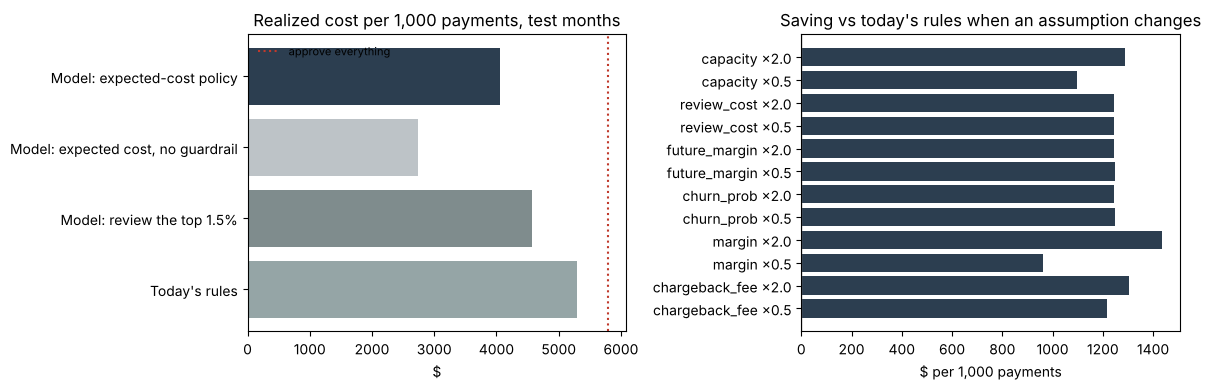

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
r = results.drop(index="Approve everything")
ax.barh(r.index, r["cost_per_1000"], color=["#95a5a6", "#7f8c8d", "#bdc3c7", "#2c3e50"])
ax.axvline(results.loc["Approve everything", "cost_per_1000"], color="#c0392b", ls=":", label="approve everything")
ax.set(title="Realized cost per 1,000 payments, test months", xlabel="$")
ax.legend(fontsize=8, frameon=False)
ax = axes[1]
sv = sens.assign(label=sens["assumption"] + " ×" + sens["factor"].astype(str))
ax.barh(sv["label"], sv["saving_per_1000"], color=np.where(sv["saving_per_1000"] > 0, "#2c3e50", "#c0392b"))
ax.axvline(0, color="grey", lw=1)
ax.set(title="Saving vs today's rules when an assumption changes", xlabel="$ per 1,000 payments")
fig.tight_layout()
data.savefig(fig, "05_policy", SOURCE)

## Record and verdict

In [9]:
record = {
    "costs": C.__dict__, "test_payments": int(len(T)), "test_frauds": int(y.sum()), "decline_threshold": TAU,
    "policies": {k: {kk: float(vv) for kk, vv in row.items()} for k, row in results.iterrows()},
    "saving_ci_per_1000": list(saving_ci), "saving_vs_model_top_per_1000": float(saving_top),
    "saving_vs_model_top_ci_per_1000": list(saving_top_ci), "guardrails": guard,
    "sensitivity": sens.to_dict(orient="records"),
    "action_mix_by_amount": {str(k): {kk: float(vv) for kk, vv in row.items()} for k, row in mix.iterrows()},
}
write_metrics("05_policy", record, SOURCE)

In [10]:
always_positive = bool((sens["saving_per_1000"] > 0).all())
worst = sens.loc[sens["saving_per_1000"].idxmin()]
def usd(x):
    return f"-${-x:,.0f}" if x < 0 else f"${x:,.0f}"


free = results.loc["Model: expected cost, no guardrail"]
top_q = results.loc["Model: review the top 1.5%"]
big = mix.loc[mix.index[-1]]
show_verdict(
    "Verdict: phase 5, the decision",
    [
        f"**The expected-cost policy costs ${pol['cost_per_1000']:,.0f} per 1,000 payments on the test months**, against "
        f"${results.loc['Approve everything', 'cost_per_1000']:,.0f} for approving everything and ${rules['cost_per_1000']:,.0f} "
        f"for the rules stand-in (saving ${pol['saving_per_1000_vs_rules']:,.0f}, 95% interval ${saving_ci[0]:,.0f} to "
        f"${saving_ci[1]:,.0f}; the stand-in is weak, see phase 3).",
        (f"**The decision layer is worth {usd(saving_top)} per 1,000 payments on its own** "
         if saving_top_ci[0] > 0 else
         f"**The decision layer's own contribution is {usd(saving_top)} per 1,000 payments, not distinguishable from zero** ")
        + f"(95% interval {usd(saving_top_ci[0])} to {usd(saving_top_ci[1])}): same model, same review capacity, but reviews "
        f"go where a review saves the most dollars rather than to the highest fraud scores. It reviews "
        f"{big.get('review', 0):.0%} of orders over $1,000; simply reviewing the top scores costs "
        f"${top_q['cost_per_1000']:,.0f}.",
        f"It stops {pol['fraud_dollars_stopped']:.0%} of fraud dollars (rules {rules['fraud_dollars_stopped']:.0%}), reviews "
        f"{pol['review_rate']:.2%} of payments and declines {pol['decline_rate']:.2%}; good customers declined "
        f"{pol['good_decline_rate']:.2%} vs {rules['good_decline_rate']:.2%} under the rules. Guardrails: "
        + ", ".join(f"{k.replace('_', ' ')} {'met' if v else 'NOT met'}" for k, v in guard.items()) + ".",
        f"**The good-customer guardrail has a price**: without it the policy would decline {free['good_decline_rate']:.2%} of "
        f"good customers and cost ${free['cost_per_1000']:,.0f} per 1,000 payments, "
        f"${pol['cost_per_1000'] - free['cost_per_1000']:,.0f} less, by these costs. Whether that is worth it depends on how "
        "much a wrongly declined customer is really worth, which the brief prices only roughly.",
        ("**The saving survives every assumption halved or doubled**; the smallest is "
         if always_positive else "**The saving changes sign when an assumption moves**: the worst case is ")
        + f"${worst['saving_per_1000']:,.0f} per 1,000 payments with {worst['assumption'].replace('_', ' ')} ×{worst['factor']}.",
    ],
    "Phase 6 measures how fast the model decays month by month, and how long label delay hides it.",
)

### Verdict: phase 5, the decision

1. **The expected-cost policy costs \$4,056 per 1,000 payments on the test months**, against \$5,795 for approving everything and \$5,299 for the rules stand-in (saving \$1,243, 95% interval \$902 to \$1,625; the stand-in is weak, see phase 3).
2. **The decision layer is worth \$510 per 1,000 payments on its own** (95% interval \$41 to \$949): same model, same review capacity, but reviews go where a review saves the most dollars rather than to the highest fraud scores. It reviews 22% of orders over \$1,000; simply reviewing the top scores costs \$4,566.
3. It stops 32% of fraud dollars (rules 12%), reviews 1.48% of payments and declines 0.28%; good customers declined 0.01% vs 0.01% under the rules. Guardrails: good decline rate not above rules NOT met, within capacity every day met, fraud loss not above rules met.
4. **The good-customer guardrail has a price**: without it the policy would decline 1.35% of good customers and cost \$2,741 per 1,000 payments, \$1,316 less, by these costs. Whether that is worth it depends on how much a wrongly declined customer is really worth, which the brief prices only roughly.
5. **The saving survives every assumption halved or doubled**; the smallest is \$961 per 1,000 payments with margin ×0.5.

**Next:** Phase 6 measures how fast the model decays month by month, and how long label delay hides it.